# 04 · Risk Scoring
**Credora Finance — Credit Risk & Loan Approval Analytics Platform**

The model outputs a probability. Underwriters need something simpler: a **0-100 score** and a **Low / Medium / High** label.

`risk_score = round(100 × calibrated probability of default)`

Code lives in **`src/risk_score.py`**. This notebook runs it, validates the labels against real outcomes, and explains the
choices. It also **writes the `scored_applications` and `scored_customers` tables to MySQL** for the dashboard.

Run `python src/train.py` (or notebook 03) first, then *Run All*.

## 1 · Score every application and customer

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 11})
pd.set_option("display.max_columns", 50, "display.width", 200)

# Works whether Jupyter was started in the project root or in notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import risk_score as R
import features as F
from data_load import get_engine

out = R.run_scoring(write=True)
app, cust, raw = out["app_scores"], out["cust_scores"], out["raw"]
lab = app[app["actual_default"].notna()].copy()          # disbursed loans with known outcome (out-of-fold scores)
lab["actual_default"] = lab["actual_default"].astype(int)
BASE = lab["actual_default"].mean() * 100

Wrote tables: scored_applications, scored_customers

Model: Logistic Regression   bands: Low <= 18, Medium <= 30, High > 30
Applications scored: 7,500   Customers scored: 5,000

Customer risk mix:  Low 1,226 (24.5%)   Medium 1,099 (22.0%)   High 2,675 (53.5%)

Honest check on disbursed loans (out-of-fold scores vs actual outcomes):
  Low     1,580 loans   actual default rate  10.3%
  Medium    956 loans   actual default rate  25.0%
  High      867 loans   actual default rate  45.7%


## 2 · How scores are spread
Scores for disbursed loans are **out-of-fold**: each loan is scored by a model that never saw it, so the validation below
is honest, not flattered by memorisation.

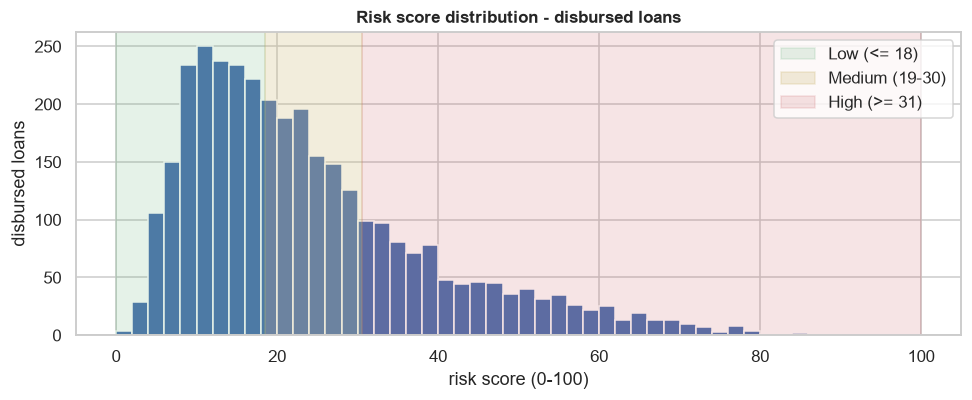

In [2]:
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.hist(lab["risk_score"], bins=np.arange(0, 101, 2), color="#4C72B0", edgecolor="white")
ax.axvspan(0, R.LOW_MAX + 0.5, color="#55A868", alpha=0.15, label=f"Low (<= {R.LOW_MAX})")
ax.axvspan(R.LOW_MAX + 0.5, R.MEDIUM_MAX + 0.5, color="#CCB974", alpha=0.25, label=f"Medium ({R.LOW_MAX + 1}-{R.MEDIUM_MAX})")
ax.axvspan(R.MEDIUM_MAX + 0.5, 100, color="#C44E52", alpha=0.15, label=f"High (>= {R.MEDIUM_MAX + 1})")
ax.set_xlabel("risk score (0-100)"); ax.set_ylabel("disbursed loans"); ax.legend()
ax.set_title("Risk score distribution - disbursed loans")
plt.tight_layout(); plt.show()

## 3 · Why not the PRD's fixed bands?
The PRD suggests 0-33 Low, 34-66 Medium, 67-100 High, and says to tune them against the confusion matrix and business
appetite. Here is how both options perform on real outcomes. A good scheme gives a **low default rate in Low, rising
steadily to High** and puts a meaningful share of loans in each band.

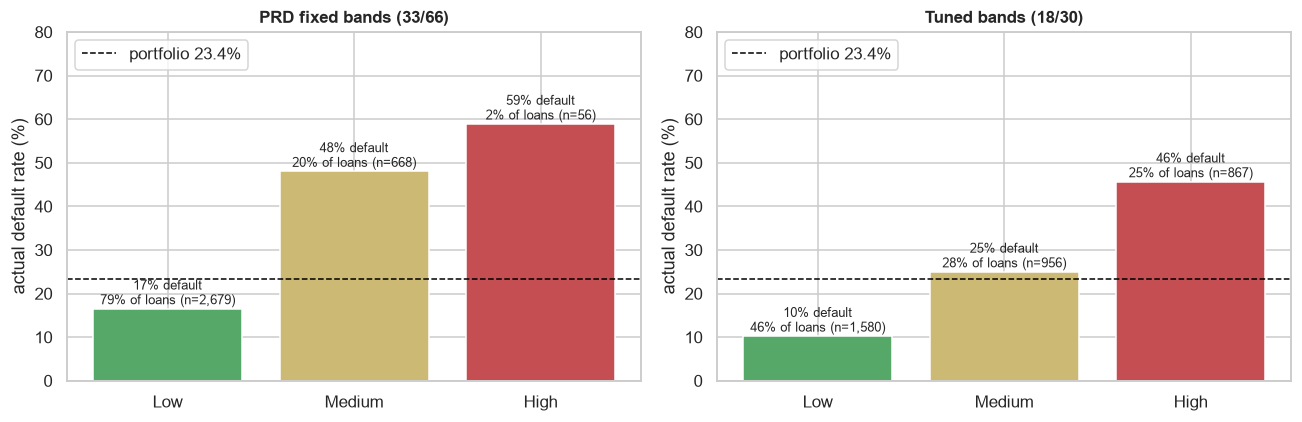

PRD bands : 79% of loans are 'Low' yet 16.5% of them default; only 1.6% reach 'High'.
Tuned     : Low 10.3%  ->  Medium 25.0%  ->  High 45.7%  (portfolio 23.4%)


In [3]:
def band_table(cats):
    t = lab.assign(band=cats).groupby("band", observed=True)["actual_default"].agg(loans="size", rate="mean").reindex(R.CATEGORIES)
    t["share"] = t["loans"] / len(lab) * 100; t["rate"] *= 100
    return t

prd = band_table(R.score_to_category(lab["risk_score"], *R.PRD_BANDS))
tuned = band_table(R.score_to_category(lab["risk_score"]))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (title, t) in zip(axes, [(f"PRD fixed bands ({R.PRD_BANDS[0]}/{R.PRD_BANDS[1]})", prd),
                                (f"Tuned bands ({R.LOW_MAX}/{R.MEDIUM_MAX})", tuned)]):
    ax.bar(t.index, t["rate"], color=["#55A868", "#CCB974", "#C44E52"])
    ax.axhline(BASE, color="black", ls="--", lw=1, label=f"portfolio {BASE:.1f}%")
    for i, (r, s, n) in enumerate(zip(t["rate"], t["share"], t["loans"])):
        ax.text(i, r + 1, f"{r:.0f}% default\n{s:.0f}% of loans (n={int(n):,})", ha="center", fontsize=8.5)
    ax.set_ylim(0, 80); ax.set_ylabel("actual default rate (%)"); ax.set_title(title); ax.legend(loc="upper left")
plt.tight_layout(); plt.show()
print(f"PRD bands : {prd.loc['Low', 'share']:.0f}% of loans are 'Low' yet {prd.loc['Low', 'rate']:.1f}% of them default; only {prd.loc['High', 'share']:.1f}% reach 'High'.")
print(f"Tuned     : Low {tuned.loc['Low', 'rate']:.1f}%  ->  Medium {tuned.loc['Medium', 'rate']:.1f}%  ->  High {tuned.loc['High', 'rate']:.1f}%  (portfolio {BASE:.1f}%)")

**Choice made:** Low ≤ 18, Medium 19-30, High ≥ 31. The logic is simple to explain: *Low* loans default at roughly **half**
the portfolio rate, *Medium* at about the portfolio rate, and *High* at roughly **double** it.

Honest caveat: the two cut-offs were picked by looking at these same out-of-fold results, so the separation shown is
slightly optimistic. With only two parameters the effect is small, but it is not zero. The cut-offs are risk-appetite
settings: change `LOW_MAX` and `MEDIUM_MAX` in `src/risk_score.py` to be stricter or looser.

## 4 · What would a cut-off policy do? (threshold analysis)
If the bank refused every loan scoring above a cut-off, how many defaulters would it avoid, and how many good customers
would it turn away?

,loans rejected %,defaulters avoided %,good loans lost %,default rate of remaining book %
reject if score >,,,,
10,81.0,95.1,76.7,6.0
15,63.4,86.8,56.3,8.4
20,47.8,75.5,39.3,11.0
25,35.1,61.9,26.9,13.8
30,25.5,49.7,18.1,15.8
35,18.9,40.2,12.4,17.3
40,13.8,30.2,8.8,19.0
45,10.5,22.1,6.9,20.4
50,7.5,15.4,5.0,21.4


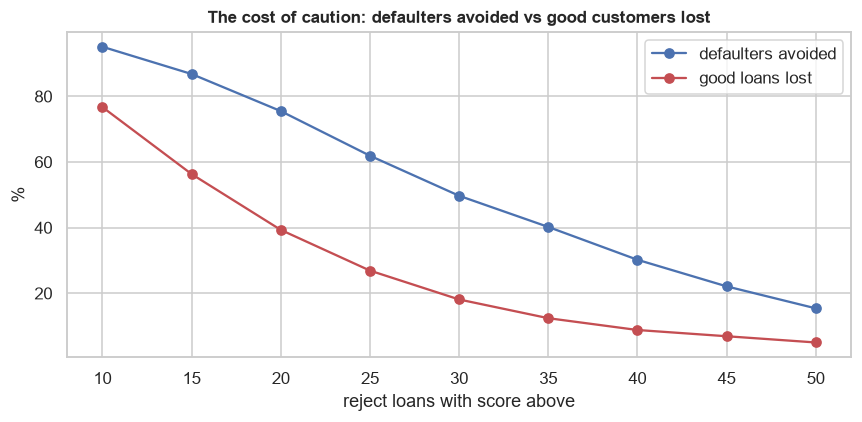

In [4]:
rows = []
for cut in range(10, 55, 5):
    flag = lab["risk_score"] > cut
    d, g = lab["actual_default"] == 1, lab["actual_default"] == 0
    rows.append({"reject if score >": cut,
                 "loans rejected %": flag.mean() * 100,
                 "defaulters avoided %": (flag & d).sum() / d.sum() * 100,
                 "good loans lost %": (flag & g).sum() / g.sum() * 100,
                 "default rate of remaining book %": lab.loc[~flag, "actual_default"].mean() * 100})
pol = pd.DataFrame(rows).round(1).set_index("reject if score >")
display(pol)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(pol.index, pol["defaulters avoided %"], "o-", color="#4C72B0", label="defaulters avoided")
ax.plot(pol.index, pol["good loans lost %"], "o-", color="#C44E52", label="good loans lost")
ax.set_xlabel("reject loans with score above"); ax.set_ylabel("%"); ax.legend()
ax.set_title("The cost of caution: defaulters avoided vs good customers lost")
plt.tight_layout(); plt.show()

Every row is a trade-off, not a right answer. A stricter cut-off lowers the default rate of the remaining book but
declines more good customers. The right point depends on the bank's margin on good loans versus its loss on defaults
(which this dataset cannot tell us).

## 5 · Does the model agree with human underwriters?
The model was trained only on **approved** loans, so it never saw a rejected application or its outcome. Yet it can
still score them. If the model has learned real risk, rejected applications should score much higher.

risk_category,Low,Medium,High
approval_status,,,
Approved,46.4,28.1,25.5
Rejected,7.7,11.5,80.8
Under Review,22.0,16.2,61.8


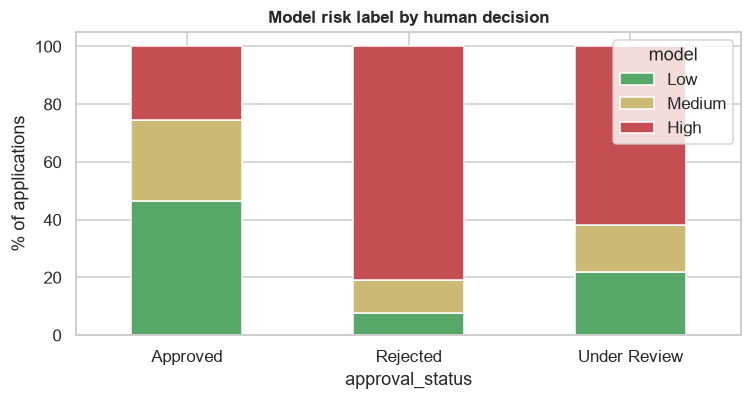

Mean score: {'Approved': 23.6, 'Rejected': 54.1, 'Under Review': 42.7}


In [5]:
status = raw["loan_applications"][["application_id", "approval_status"]]
a = app.merge(status, on="application_id")
mix = (pd.crosstab(a["approval_status"], a["risk_category"], normalize="index") * 100)[R.CATEGORIES].round(1)
display(mix)
mix.plot(kind="bar", stacked=True, figsize=(7, 3.8), color=["#55A868", "#CCB974", "#C44E52"])
plt.ylabel("% of applications"); plt.xticks(rotation=0); plt.title("Model risk label by human decision"); plt.legend(title="model")
plt.tight_layout(); plt.show()
print("Mean score:", a.groupby("approval_status")["risk_score"].mean().round(1).to_dict())

Rejected applications are overwhelmingly labelled High, so the model independently reproduces much of the underwriters'
judgement, which is a good sign.

**Caveat (reject inference).** The model never saw outcomes for rejected or under-review applications. Their scores are
extrapolations to riskier applicants than it trained on, and their **calibration cannot be verified**. Treat those scores as a
relative ranking, not a precise probability.

## 6 · Customer-level risk
A customer's score is the **mean probability across their applications**. 1,096 customers never applied, so they are scored
from their bureau, demographic and transaction profile alone (loan fields are filled with portfolio medians) and labelled
`profile only`.

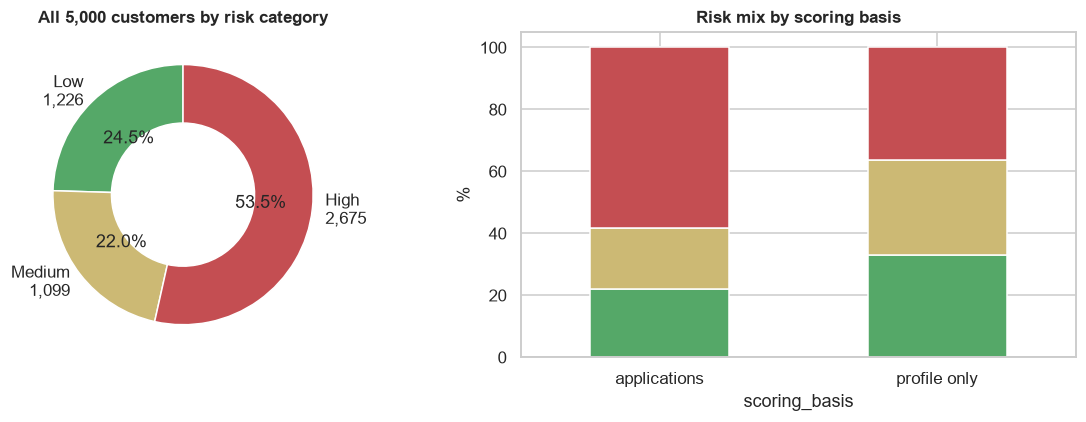

{'applications': 3904, 'profile only': 1096}


In [6]:
cdet = cust.merge(raw["customers"][["customer_id", "city", "state", "employment_type", "annual_income"]], on="customer_id")
mix_c = cust["risk_category"].value_counts().reindex(R.CATEGORIES)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].pie(mix_c.values, labels=[f"{k}\n{v:,}" for k, v in mix_c.items()], autopct="%1.1f%%",
            colors=["#55A868", "#CCB974", "#C44E52"], startangle=90, wedgeprops={"width": 0.45, "edgecolor": "white"})
axes[0].set_title(f"All {len(cust):,} customers by risk category")
b = (pd.crosstab(cust["scoring_basis"], cust["risk_category"], normalize="index") * 100)[R.CATEGORIES]
b.plot(kind="bar", stacked=True, ax=axes[1], color=["#55A868", "#CCB974", "#C44E52"], legend=False)
axes[1].set_title("Risk mix by scoring basis"); axes[1].set_ylabel("%"); axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()
print(cust["scoring_basis"].value_counts().to_dict())

**Why is the High share large?** Customer scores include their rejected and under-review applications, which score much higher
(section 5). So the customer-level High share reflects the applicant pool, not only the approved book. For the
disbursed book, the High share is about a quarter (section 3). The dashboard should make this distinction clear.

In [7]:
by_emp = (cdet.assign(high=cdet["risk_category"].eq("High")).groupby("employment_type")
          .agg(customers=("customer_id", "size"), high_risk_pct=("high", "mean"), avg_score=("risk_score", "mean")))
by_emp["high_risk_pct"] *= 100
display(by_emp.sort_values("high_risk_pct", ascending=False).round(1))

,customers,high_risk_pct,avg_score
employment_type,,,
Unemployed,272,98.5,70.5
Retired,352,75.6,48.8
Self-Employed,1040,62.5,41.2
Business Owner,629,44.8,32.7
Salaried,2707,44.7,32.2


**Caution on "Unemployed".** Almost every unemployed customer scores High, but only 24 of the 3,403 training loans were to
unemployed borrowers (under 1%). The model has very little direct evidence about this group, so its scores here are closer to
extrapolation than to learned experience. The *ranking* is plausible; the *precise level* is not reliable.

## 7 · High-risk watchlist (top 15)
No names, emails or phone numbers — customer ID and non-sensitive attributes only.

In [8]:
watch = (cdet[cdet["risk_category"] == "High"]
         .sort_values(["risk_score", "n_applications"], ascending=False)
         .head(15)[["customer_id", "city", "state", "employment_type", "n_applications", "risk_score", "scoring_basis"]])
watch.reset_index(drop=True)

,customer_id,city,state,employment_type,n_applications,risk_score,scoring_basis
0,CUST102637,Surat,Gujarat,Unemployed,3,99,applications
1,CUST103248,Jaipur,Rajasthan,Unemployed,2,97,applications
2,CUST100103,Kolkata,West Bengal,Unemployed,1,97,applications
3,CUST100951,Chandigarh,Chandigarh,Unemployed,1,97,applications
4,CUST101157,Mysuru,Karnataka,Self-Employed,1,97,applications
5,CUST102875,Bengaluru,Karnataka,Business Owner,1,97,applications
6,CUST102586,Chennai,Tamil Nadu,Business Owner,2,96,applications
7,CUST100002,Mysuru,Karnataka,Unemployed,1,96,applications
8,CUST101256,Noida,Uttar Pradesh,Unemployed,1,96,applications
9,CUST104504,Mumbai,Maharashtra,Retired,1,96,applications


## 8 · Check the MySQL tables the dashboard will read

In [9]:
from sqlalchemy import text
eng = get_engine()
with eng.connect() as c:
    for t in ["scored_customers", "scored_applications"]:
        print(f"{t}: {c.execute(text(f'SELECT COUNT(*) FROM {t}')).scalar():,} rows")
q = '''
SELECT sc.risk_category,
       COUNT(*)                         AS customers,
       ROUND(AVG(sc.risk_score), 1)     AS avg_score,
       ROUND(AVG(c.annual_income), 0)   AS avg_income
FROM scored_customers sc
JOIN customers c USING (customer_id)
GROUP BY sc.risk_category
ORDER BY avg_score
'''
pd.read_sql(q, eng)

scored_customers: 5,000 rows
scored_applications: 7,500 rows


,risk_category,customers,avg_score,avg_income
0,Low,1226,12.3,973425.0
1,Medium,1099,24.3,590623.0
2,High,2675,54.2,394529.0


## 9 · Summary and caveats
| Item | Result |
|---|---|
| Score | `round(100 × calibrated P(default))`, 0-100 |
| Bands | Low ≤ 18, Medium 19-30, High ≥ 31 (tuned; PRD's fixed bands left 79% of loans in "Low") |
| Honest validation | Out-of-fold scores: default rate rises Low → Medium → High on real outcomes |
| Tables written | `scored_applications` (7,500) and `scored_customers` (5,000) |

**Limits to state in the README and model card**
1. Scores for rejected / under-review applications are extrapolations (no outcome labels).
2. 1,096 customers are scored on profile only (`scoring_basis = 'profile only'`); small groups such as unemployed borrowers (24 training loans) are weakly supported.
3. Band cut-offs were tuned on the same out-of-fold data (small optimism).
4. Bureau/transaction snapshots are from 2024; many loans date from 2022.
5. The model's ROC-AUC is about 0.72-0.74 (see notebook 03), so scores rank risk usefully but imperfectly.

**Next:** the Streamlit dashboard reads `scored_customers` and `scored_applications` plus the base tables.